# Keşifsel Veri Analizi (EDA) – Census-Income (KDD)

Bu notebook, **Census-Income (KDD)** veri seti üzerinde görsel keşifsel veri analizi yapar.
`analysis/pre_analiz.py` (temizleme / ön analiz) ve `analysis/turetilmis_ozellikler.py`
(türetilmiş özellikler) scriptlerindeki fonksiyonları **yeniden kullanır**; böylece notebook
ile scriptler aynı kurallarla çalışır.

**Amaç:** Bir kişinin yıllık gelirinin **50.000 $ üzerinde** olup olmadığını (`income_over_50k`)
etkileyen faktörleri anlamak; veritabanı tasarımı ve ML modeli için karar girdisi üretmek.

| Bölüm | İçerik |
|---|---|
| 1 | Kurulum ve veri yükleme |
| 2 | Genel bakış |
| 3 | Hedef değişken |
| 4 | Eksik değerler ve "Not in universe" |
| 5 | Sayısal değişkenler |
| 6 | Kategorik değişkenler ve gelir ilişkisi |
| 7 | İki değişkenli / etkileşim analizleri |
| 8 | Korelasyon ve ilişki gücü (Pearson, Cramér's V, Mutual Information) |
| 9 | Türetilmiş özellikler |
| 10 | Train – test dağılım karşılaştırması |
| 11 | Aykırı ve kesilmiş (top-coded) değerler |
| 12 | Özet bulgular ve öneriler |

## 1. Kurulum ve Veri Yükleme

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

# Notebook proje kökünden ya da analysis/ klasöründen açılabilir
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "analysis"))

from pre_analiz import load, NUMERIC_COLS, CODED_CATEGORICAL_COLS, TARGET
from turetilmis_ozellikler import add_derived_features, DERIVED_COLS, AGE_LABELS, EDUCATION_LEVELS

In [2]:
# --- Grafik stili ---------------------------------------------------------
C_LOW, C_HIGH = "#2a78d6", "#eb6834"      # 50K altı (0) / 50K üstü (1)
C_MAIN = "#2a78d6"                         # tek seri grafikler
C_GRID, C_INK, C_MUTED = "#e4e3df", "#0b0b0b", "#52514e"
CLASS_COLORS = {0: C_LOW, 1: C_HIGH}
CLASS_NAMES = {0: "50K altı", 1: "50K üstü"}
SEQ = LinearSegmentedColormap.from_list("seq", ["#eef4fc", "#2a78d6", "#0d3a73"])
DIV = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f2f1ee", "#2a78d6"])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": C_GRID, "axes.labelcolor": C_MUTED, "axes.titlecolor": C_INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.6,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED, "legend.frameon": False,
    "font.size": 9,
})

def pct_axis(ax, axis="y"):
    fmt = mticker.PercentFormatter(100, decimals=0)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

def rate_bar(ax, s, title, base_rate=None, color=C_MAIN, label_fmt="{:.1f}%"):
    # Yatay bar: kategori -> 50K+ oranı (%), değer etiketli
    ax.barh(s.index.astype(str), s.values, color=color, height=0.7)
    for i, v in enumerate(s.values):
        ax.text(v + s.max() * 0.01, i, label_fmt.format(v), va="center", fontsize=8, color=C_MUTED)
    if base_rate is not None:
        ax.axvline(base_rate, color=C_MUTED, ls="--", lw=1)
        ax.text(base_rate, len(s) - 0.4, f" genel ort. {base_rate:.1f}%", fontsize=8, color=C_MUTED)
    ax.set_title(title); ax.grid(axis="y", visible=False); pct_axis(ax, "x")
    ax.invert_yaxis()

In [3]:
# Ham veriyi pre_analiz.py ile aynı kurallarla oku: '?' -> NaN, hedef -> 0/1
train_raw = load(ROOT / "data" / "census-income.data")
test_raw = load(ROOT / "data" / "census-income.test")

# Birebir aynı satırları sil (pre_analiz.py kararı) ve türetilmiş özellikleri ekle
train = add_derived_features(train_raw.drop_duplicates().reset_index(drop=True))
test = add_derived_features(test_raw.drop_duplicates().reset_index(drop=True))

CAT_COLS = [c for c in train_raw.columns if c not in NUMERIC_COLS + [TARGET]]
BASE_RATE = 100 * train[TARGET].mean()
print(f"train: {train_raw.shape} -> tekilleştirme sonrası {train.shape}")
print(f"test : {test_raw.shape} -> tekilleştirme sonrası {test.shape}")

train: (199523, 42) -> tekilleştirme sonrası (196294, 51)
test : (99762, 42) -> tekilleştirme sonrası (98879, 51)


## 2. Genel Bakış

In [4]:
train.head()

,age,class_of_worker,detailed_industry_recode,detailed_occupation_recode,education,wage_per_hour,enroll_in_edu_inst_last_wk,marital_stat,major_industry_code,major_occupation_code,race,hispanic_origin,sex,member_of_labor_union,reason_for_unemployment,full_or_part_time_employment_stat,capital_gains,capital_losses,dividends_from_stocks,tax_filer_stat,region_of_previous_residence,state_of_previous_residence,detailed_household_and_family_stat,detailed_household_summary_in_household,instance_weight,migration_code_change_in_msa,migration_code_change_in_reg,migration_code_move_within_reg,live_in_this_house_1_year_ago,migration_prev_res_in_sunbelt,num_persons_worked_for_employer,family_members_under_18,country_of_birth_father,country_of_birth_mother,country_of_birth_self,citizenship,own_business_or_self_employed,fill_inc_questionnaire_for_veterans_admin,veterans_benefits,weeks_worked_in_year,year,income_over_50k,education_level,age_group,is_employed,full_year_worker,is_professional_occ,has_investment,is_householder,joint_filer,is_married
0,73,Not in universe,0,0,High school graduate,0,Not in universe,Widowed,Not in universe or children,Not in universe,White,All other,Female,Not in universe,Not in universe,Not in labor force,0,0,0,Nonfiler,Not in universe,Not in universe,Other Rel 18+ ever marr not in subfamily,Other relative of householder,"1,700.090",NaN,NaN,NaN,Not in universe under 1 year old,NaN,0,Not in universe,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,2,0,95,0,9,65+,0,0,0,0,0,0,0
1,58,Self-employed-not incorporated,4,34,Some college but no degree,0,Not in universe,Divorced,Construction,Precision production craft & repair,White,All other,Male,Not in universe,Not in universe,Children or Armed Forces,0,0,0,Head of household,South,Arkansas,Householder,Householder,"1,053.550",MSA to MSA,Same county,Same county,No,Yes,1,Not in universe,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,2,52,94,0,10,55-64,1,1,0,0,1,0,0
2,18,Not in universe,0,0,10th grade,0,High school,Never married,Not in universe or children,Not in universe,Asian or Pacific Islander,All other,Female,Not in universe,Not in universe,Not in labor force,0,0,0,Nonfiler,Not in universe,Not in universe,Child 18+ never marr Not in a subfamily,Child 18 or older,991.950,NaN,NaN,NaN,Not in universe under 1 year old,NaN,0,Not in universe,Vietnam,Vietnam,Vietnam,Foreign born- Not a citizen of U S,0,Not in universe,2,0,95,0,6,18-24,0,0,0,0,0,0,0
3,9,Not in universe,0,0,Children,0,Not in universe,Never married,Not in universe or children,Not in universe,White,All other,Female,Not in universe,Not in universe,Children or Armed Forces,0,0,0,Nonfiler,Not in universe,Not in universe,Child <18 never marr not in subfamily,Child under 18 never married,"1,758.140",Nonmover,Nonmover,Nonmover,Yes,Not in universe,0,Both parents present,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,0,0,94,0,0,0-17,0,0,0,0,0,0,0
4,10,Not in universe,0,0,Children,0,Not in universe,Never married,Not in universe or children,Not in universe,White,All other,Female,Not in universe,Not in universe,Children or Armed Forces,0,0,0,Nonfiler,Not in universe,Not in universe,Child <18 never marr not in subfamily,Child under 18 never married,"1,069.160",Nonmover,Nonmover,Nonmover,Yes,Not in universe,0,Both parents present,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,0,0,94,0,0,0-17,0,0,0,0,0,0,0


In [5]:
overview = pd.DataFrame({
    "tip": ["sayısal" if c in NUMERIC_COLS else "kod (kategorik)" if c in CODED_CATEGORICAL_COLS
            else "hedef" if c == TARGET else "türetilmiş" if c in DERIVED_COLS else "kategorik"
            for c in train.columns],
    "dtype": train.dtypes.astype(str).values,
    "farklı değer": train.nunique().values,
    "eksik %": (100 * train.isna().mean()).values,
    "en sık değer": [str(train[c].mode(dropna=True).iloc[0])[:40] for c in train.columns],
    "en sık %": [100 * train[c].value_counts(normalize=True, dropna=False).iloc[0] for c in train.columns],
}, index=train.columns)
print(f"Bellek: {train.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
overview.sort_values("tip")

Bellek: 375 MB


,tip,dtype,farklı değer,eksik %,en sık değer,en sık %
income_over_50k,hedef,int8,2,0.000,0,93.692
migration_code_change_in_msa,kategorik,str,9,49.933,Nonmover,49.933
country_of_birth_father,kategorik,str,42,3.415,United-States,79.491
family_members_under_18,kategorik,str,5,0.000,Not in universe,73.441
citizenship,kategorik,str,5,0.000,Native- Born in the United States,88.534
migration_prev_res_in_sunbelt,kategorik,str,3,49.933,Not in universe,49.933
live_in_this_house_1_year_ago,kategorik,str,3,0.000,Not in universe under 1 year old,50.656
migration_code_move_within_reg,kategorik,str,9,49.933,Nonmover,49.933
migration_code_change_in_reg,kategorik,str,8,49.933,Nonmover,49.933
fill_inc_questionnaire_for_veterans_admin,kategorik,str,3,0.000,Not in universe,98.989


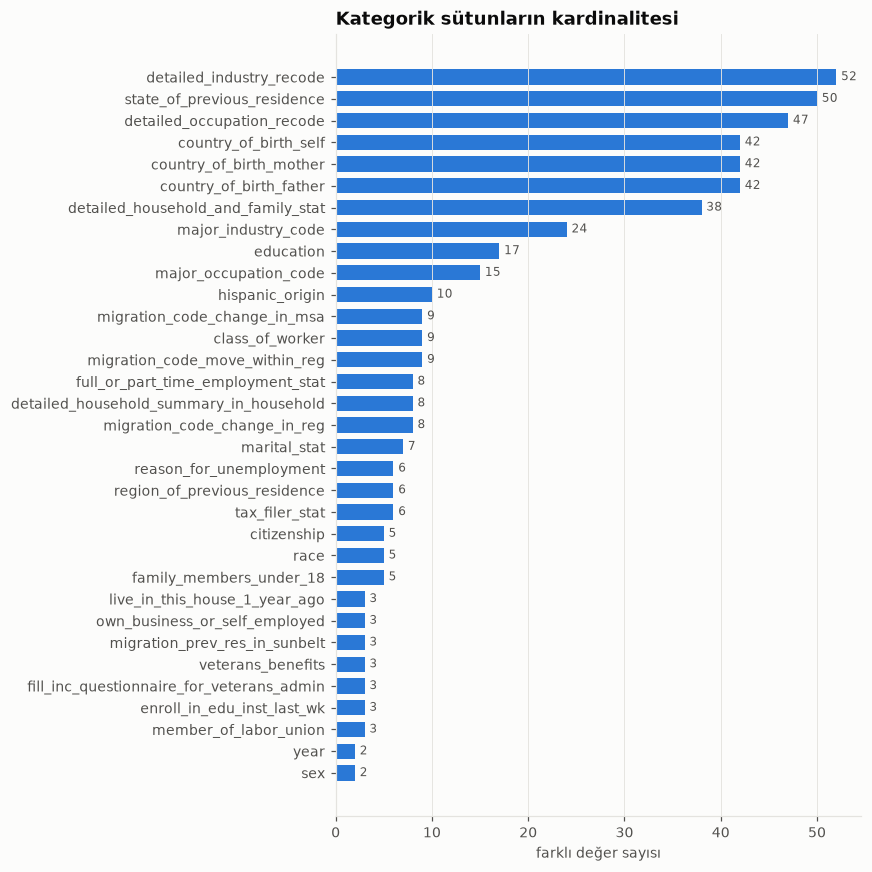

In [6]:
# Kardinalite: kategorik sütunların farklı değer sayısı
card = train[CAT_COLS].nunique().sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(card.index, card.values, color=C_MAIN, height=0.7)
for i, v in enumerate(card.values):
    ax.text(v + 0.5, i, str(v), va="center", fontsize=8, color=C_MUTED)
ax.set_title("Kategorik sütunların kardinalitesi")
ax.set_xlabel("farklı değer sayısı"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

> Kardinalitesi yüksek sütunlar (`detailed_*_recode`, `country_of_birth_*`, `state_of_previous_residence`)
> modelde doğrudan one-hot kodlanırsa çok sayıda seyrek sütun üretir; bunlar için gruplama,
> hedef kodlama (target encoding) ya da üst seviye (`major_*`) kodların kullanılması düşünülmeli.

## 3. Hedef Değişken

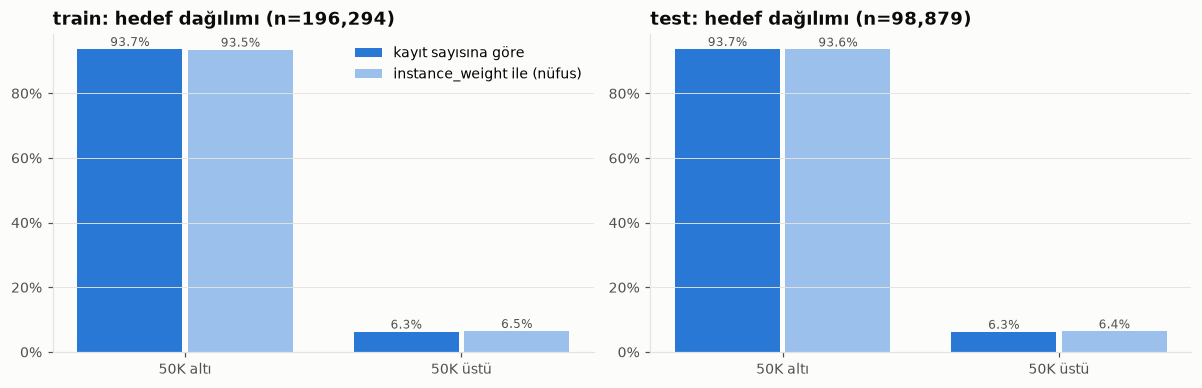

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (name, df) in zip(axes, [("train", train), ("test", test)]):
    raw = 100 * df[TARGET].value_counts(normalize=True).sort_index()
    w = df.groupby(TARGET)["instance_weight"].sum(); w = 100 * w / w.sum()
    x = np.arange(2); bw = 0.38
    b1 = ax.bar(x - bw / 2 - 0.01, raw.values, bw, color=C_MAIN, label="kayıt sayısına göre")
    b2 = ax.bar(x + bw / 2 + 0.01, w.values, bw, color="#9bc0ec", label="instance_weight ile (nüfus)")
    ax.bar_label(b1, fmt="%.1f%%", fontsize=8, color=C_MUTED)
    ax.bar_label(b2, fmt="%.1f%%", fontsize=8, color=C_MUTED)
    ax.set_xticks(x, [CLASS_NAMES[0], CLASS_NAMES[1]]); pct_axis(ax)
    ax.set_title(f"{name}: hedef dağılımı (n={len(df):,})"); ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper right")
plt.tight_layout(); plt.show()

**Yorum:** Sınıflar çok dengesiz (~%6 pozitif). Her kayda "50K altı" diyen bir model bile ~%94
doğruluk alır. Değerlendirmede **ROC-AUC, PR-AUC, F1, Precision/Recall** kullanılmalı; eğitimde
`class_weight='balanced'` veya yeniden örnekleme düşünülmeli. Ağırlıklı (nüfus) oran ile kayıt
bazlı oran birbirine yakın, yani örnekleme ağırlığı hedef dağılımını ciddi biçimde değiştirmiyor.

## 4. Eksik Değerler ve "Not in universe"

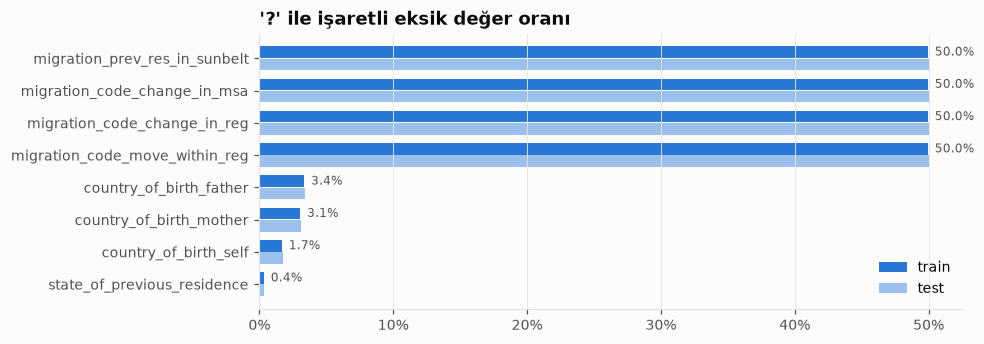

In [8]:
miss = pd.DataFrame({"train": 100 * train_raw.isna().mean(), "test": 100 * test_raw.isna().mean()})
miss = miss[(miss > 0).any(axis=1)].sort_values("train")

fig, ax = plt.subplots(figsize=(9, 3.2))
y = np.arange(len(miss)); bh = 0.36
ax.barh(y + bh / 2 + 0.01, miss["train"], bh, color=C_MAIN, label="train")
ax.barh(y - bh / 2 - 0.01, miss["test"], bh, color="#9bc0ec", label="test")
for i, v in enumerate(miss["train"]):
    ax.text(v + 0.5, i + bh / 2, f"{v:.1f}%", va="center", fontsize=8, color=C_MUTED)
ax.set_yticks(y, miss.index); pct_axis(ax, "x"); ax.grid(axis="y", visible=False)
ax.set_title("'?' ile işaretli eksik değer oranı"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

In [9]:
# migration_* eksikliği yıla bağlı mı?
mig = [c for c in train_raw.columns if c.startswith("migration_")]
(100 * train_raw.groupby("year")[mig].apply(lambda g: g.isna().mean())).round(1)

,migration_code_change_in_msa,migration_code_change_in_reg,migration_code_move_within_reg,migration_prev_res_in_sunbelt
year,,,,
94,0.000,0.000,0.000,0.000
95,100.000,100.000,100.000,100.000


> `migration_*` sütunları **1995 kayıtlarında tamamen boş**, 1994'te hiç eksik yok. Bu rastgele bir
> eksiklik değil (MNAR / yapısal): 1995 anketinde soru sorulmamış. Doldurmak (imputation) yanıltıcı
> olur; sütunlar ya modelden çıkarılmalı ya da eksiklik ayrı bir `Unknown` kategorisi olarak tutulmalı.

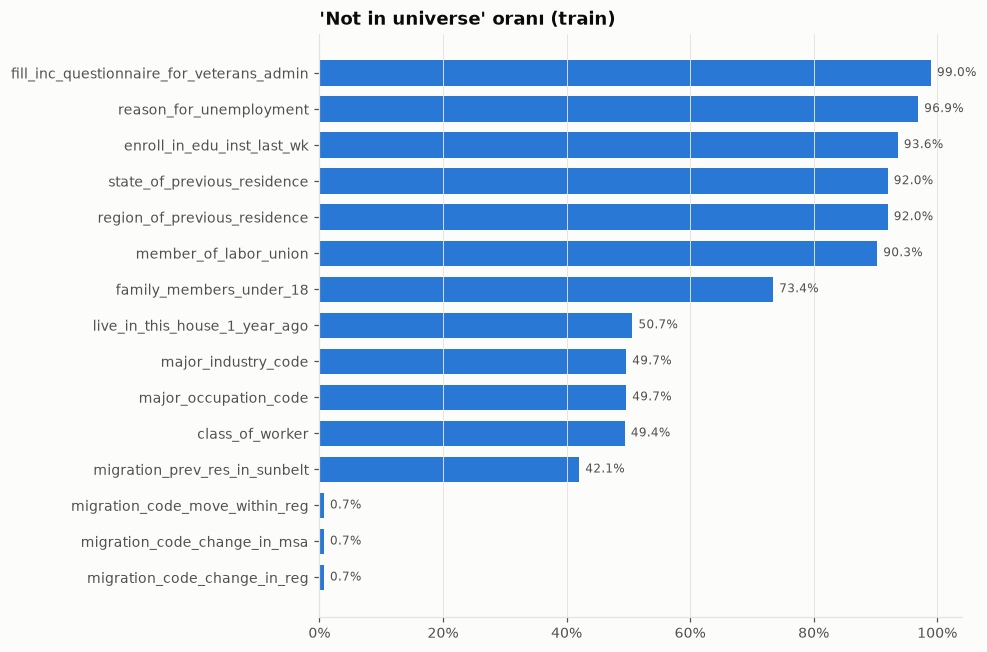

In [10]:
# 'Not in universe' = soru o kişiye uygulanmıyor (eksik değil, ayrı bir kategori)
obj_cols = train.select_dtypes(include=["object", "string"]).columns
niu = pd.Series({c: 100 * train[c].astype(str).str.startswith("Not in universe").mean() for c in obj_cols})
niu = niu[niu > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
rate_bar(ax, niu, "'Not in universe' oranı (train)")
plt.tight_layout(); plt.show()

In [11]:
# 'Not in universe' satırlarının gelir oranı: bu kategori bilgi taşıyor mu?
rows = []
for c in niu.index[:10]:
    m = train[c].astype(str).str.startswith("Not in universe")
    rows.append({"sütun": c, "NIU 50K+ %": 100 * train.loc[m, TARGET].mean(),
                 "diğer 50K+ %": 100 * train.loc[~m, TARGET].mean()})
pd.DataFrame(rows).set_index("sütun")

,NIU 50K+ %,diğer 50K+ %
sütun,,
fill_inc_questionnaire_for_veterans_admin,6.253,11.643
reason_for_unemployment,6.420,2.802
enroll_in_edu_inst_last_wk,6.722,0.239
state_of_previous_residence,6.515,3.928
region_of_previous_residence,6.515,3.928
member_of_labor_union,5.726,11.720
family_members_under_18,8.588,0.004
live_in_this_house_1_year_ago,6.580,6.028
major_industry_code,0.930,11.612


> "Not in universe" çoğunlukla çocukları ve iş gücü dışındaki kişileri işaret eder. Sütuna göre
> anlamı değişir: `major_industry/occupation_code` için NIU güçlü bir **düşük gelir** sinyali iken,
> `enroll_in_edu_inst_last_wk` veya `family_members_under_18` için NIU (= yetişkin, okula gitmiyor)
> daha **yüksek** gelirle ilişkili. Her iki durumda da bilgi taşıdığı için NULL'a çevrilmemeli,
> ayrı kategori olarak kalmalı.

## 5. Sayısal Değişkenler

In [12]:
num = train[NUMERIC_COLS]
desc = num.describe(percentiles=[.25, .5, .75, .9, .99]).T
desc["sıfır %"] = 100 * (num == 0).mean()
desc["çarpıklık"] = num.skew()
desc["basıklık"] = num.kurt()
desc

,count,mean,std,min,25%,50%,75%,90%,99%,max,sıfır %,çarpıklık,basıklık
age,"196,294.000",34.929,22.210,0.000,16.000,34.000,50.000,68.000,85.000,90.000,1.346,0.357,-0.727
wage_per_hour,"196,294.000",56.337,277.054,0.000,0.000,0.000,0.000,0.000,"1,400.000","9,999.000",94.242,8.862,152.753
capital_gains,"196,294.000",441.870,"4,735.677",0.000,0.000,0.000,0.000,0.000,"8,614.000","99,999.000",96.241,18.836,386.649
capital_losses,"196,294.000",37.928,274.081,0.000,0.000,0.000,0.000,0.000,"1,887.000","4,608.000",98.010,7.567,60.559
dividends_from_stocks,"196,294.000",200.722,"2,000.131",0.000,0.000,0.000,0.000,10.000,"4,800.000","99,999.000",89.231,27.567,"1,073.303"
instance_weight,"196,294.000","1,743.268",996.946,37.870,"1,061.530","1,620.175","2,194.060","3,068.660","4,797.845","18,656.300",0.000,1.431,5.396
num_persons_worked_for_employer,"196,294.000",1.988,2.371,0.000,0.000,1.000,4.000,6.000,6.000,6.000,47.261,0.727,-1.118
weeks_worked_in_year,"196,294.000",23.554,24.429,0.000,0.000,12.000,52.000,52.000,52.000,52.000,47.261,0.181,-1.874


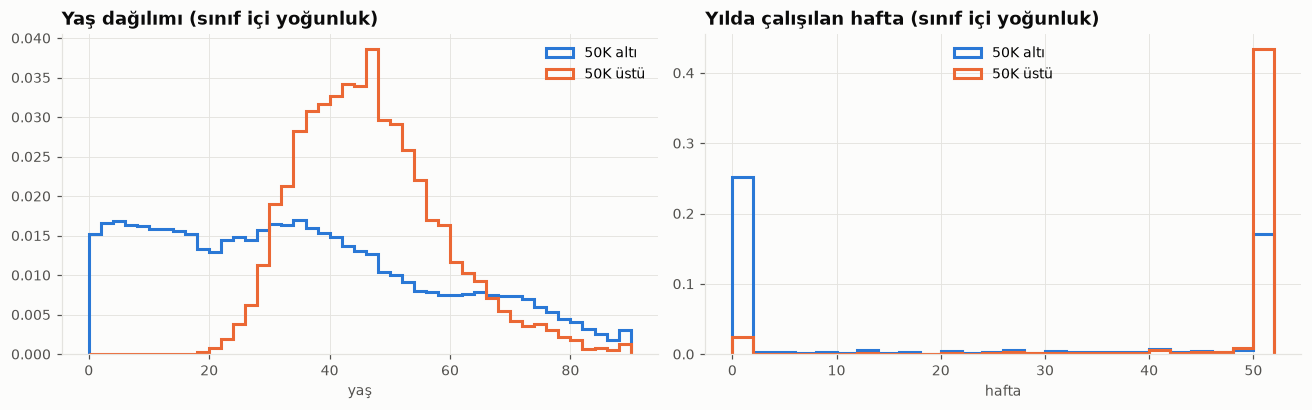

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for t in [0, 1]:
    axes[0].hist(train.loc[train[TARGET] == t, "age"], bins=range(0, 92, 2), density=True,
                 histtype="step", lw=2, color=CLASS_COLORS[t], label=CLASS_NAMES[t])
axes[0].set_title("Yaş dağılımı (sınıf içi yoğunluk)"); axes[0].set_xlabel("yaş"); axes[0].legend()

for t in [0, 1]:
    axes[1].hist(train.loc[train[TARGET] == t, "weeks_worked_in_year"], bins=range(0, 54, 2),
                 density=True, histtype="step", lw=2, color=CLASS_COLORS[t], label=CLASS_NAMES[t])
axes[1].set_title("Yılda çalışılan hafta (sınıf içi yoğunluk)"); axes[1].set_xlabel("hafta")
axes[1].legend(loc="upper center")
plt.tight_layout(); plt.show()

> **Yaş:** 50K+ grubu 35–60 yaş arasında yoğunlaşıyor; 50K altı grubunda çocuklar (0–17) büyük pay
> tutuyor. **Çalışılan hafta:** dağılım iki tepeli – ya 0 hafta ya da 52 hafta. 50K+ kişilerin çok
> büyük kısmı yılın tamamında çalışıyor.

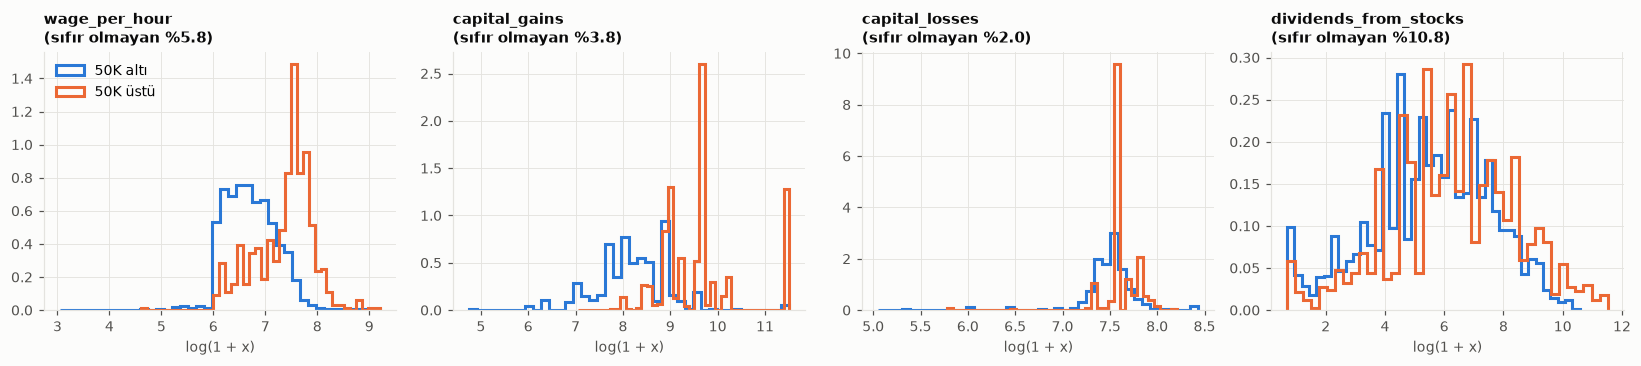

In [14]:
# Para birimli sütunlar: çoğu sıfır, sıfır olmayanlar çok çarpık -> log1p
money = ["wage_per_hour", "capital_gains", "capital_losses", "dividends_from_stocks"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, c in zip(axes, money):
    nz = train[train[c] > 0]
    for t in [0, 1]:
        ax.hist(np.log1p(nz.loc[nz[TARGET] == t, c]), bins=40, density=True, histtype="step",
                lw=2, color=CLASS_COLORS[t], label=CLASS_NAMES[t])
    ax.set_title(f"{c}\n(sıfır olmayan %{100 * (train[c] > 0).mean():.1f})", fontsize=10)
    ax.set_xlabel("log(1 + x)")
axes[0].legend()
plt.tight_layout(); plt.show()

In [15]:
# Sıfır mı değil mi? -> 50K+ oranı
tbl = pd.DataFrame({c: [100 * train.loc[train[c] == 0, TARGET].mean(),
                        100 * train.loc[train[c] > 0, TARGET].mean()] for c in money},
                   index=["= 0  → 50K+ %", "> 0  → 50K+ %"]).T
tbl

,= 0 → 50K+ %,> 0 → 50K+ %
wage_per_hour,6.393,4.919
capital_gains,5.278,32.687
capital_losses,5.828,29.928
dividends_from_stocks,4.037,25.125


> `capital_gains`, `capital_losses` ve `dividends_from_stocks` sütunlarında değerin **0'dan büyük
> olması** 50K+ oranını ~5–8 kat artırıyor. `wage_per_hour` ise ters yönde: saatlik ücret bildirenler
> genelde saat ücretli işçiler, yüksek gelirliler ise maaşlı – bu yüzden `> 0` olanlarda oran daha düşük. Modelde ham değer yerine
> `log1p(x)` dönüşümü + "x > 0" bayrağı kullanmak faydalı olur (`has_investment` türetilmiş
> özelliği bu fikre dayanıyor).

## 6. Kategorik Değişkenler ve Gelir İlişkisi

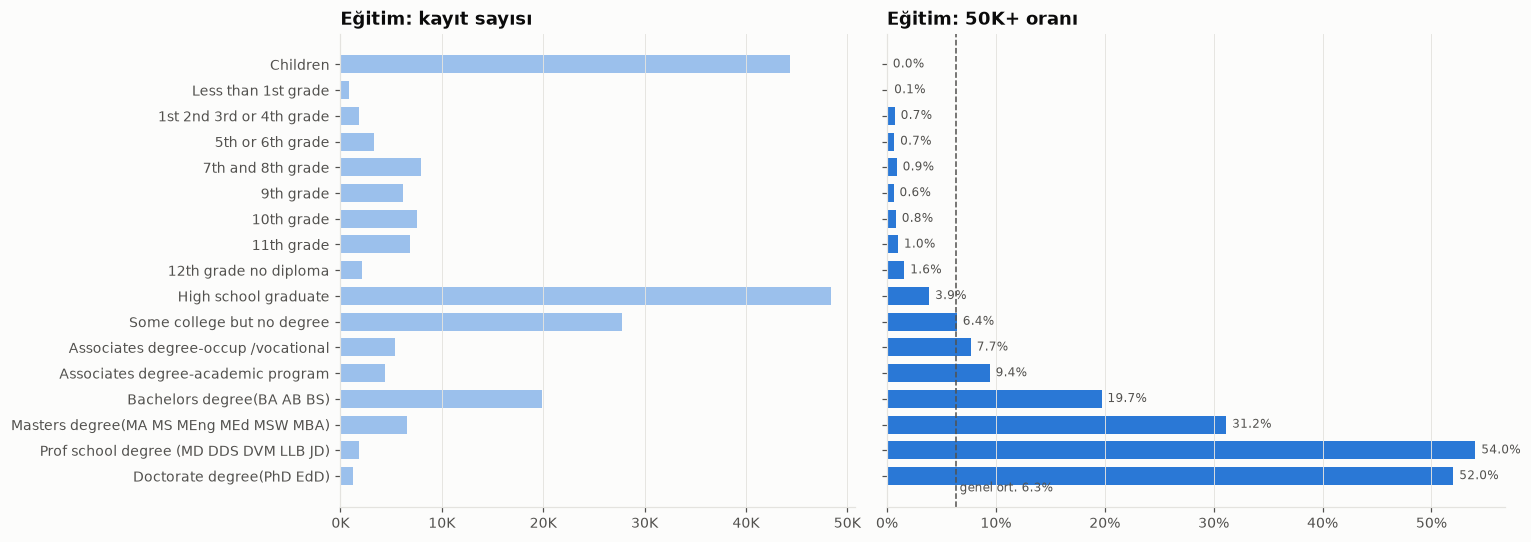

In [16]:
# Eğitim düzeyi - sıralı (education_level) olarak
g = train.groupby("education")[TARGET].agg(["size", "mean"])
g["level"] = g.index.map(EDUCATION_LEVELS); g = g.sort_values("level")
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].barh(g.index, g["size"], color="#9bc0ec", height=0.7)
axes[0].set_title("Eğitim: kayıt sayısı"); axes[0].invert_yaxis(); axes[0].grid(axis="y", visible=False)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v / 1000:.0f}K"))
rate_bar(axes[1], 100 * g["mean"], "Eğitim: 50K+ oranı", BASE_RATE)
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

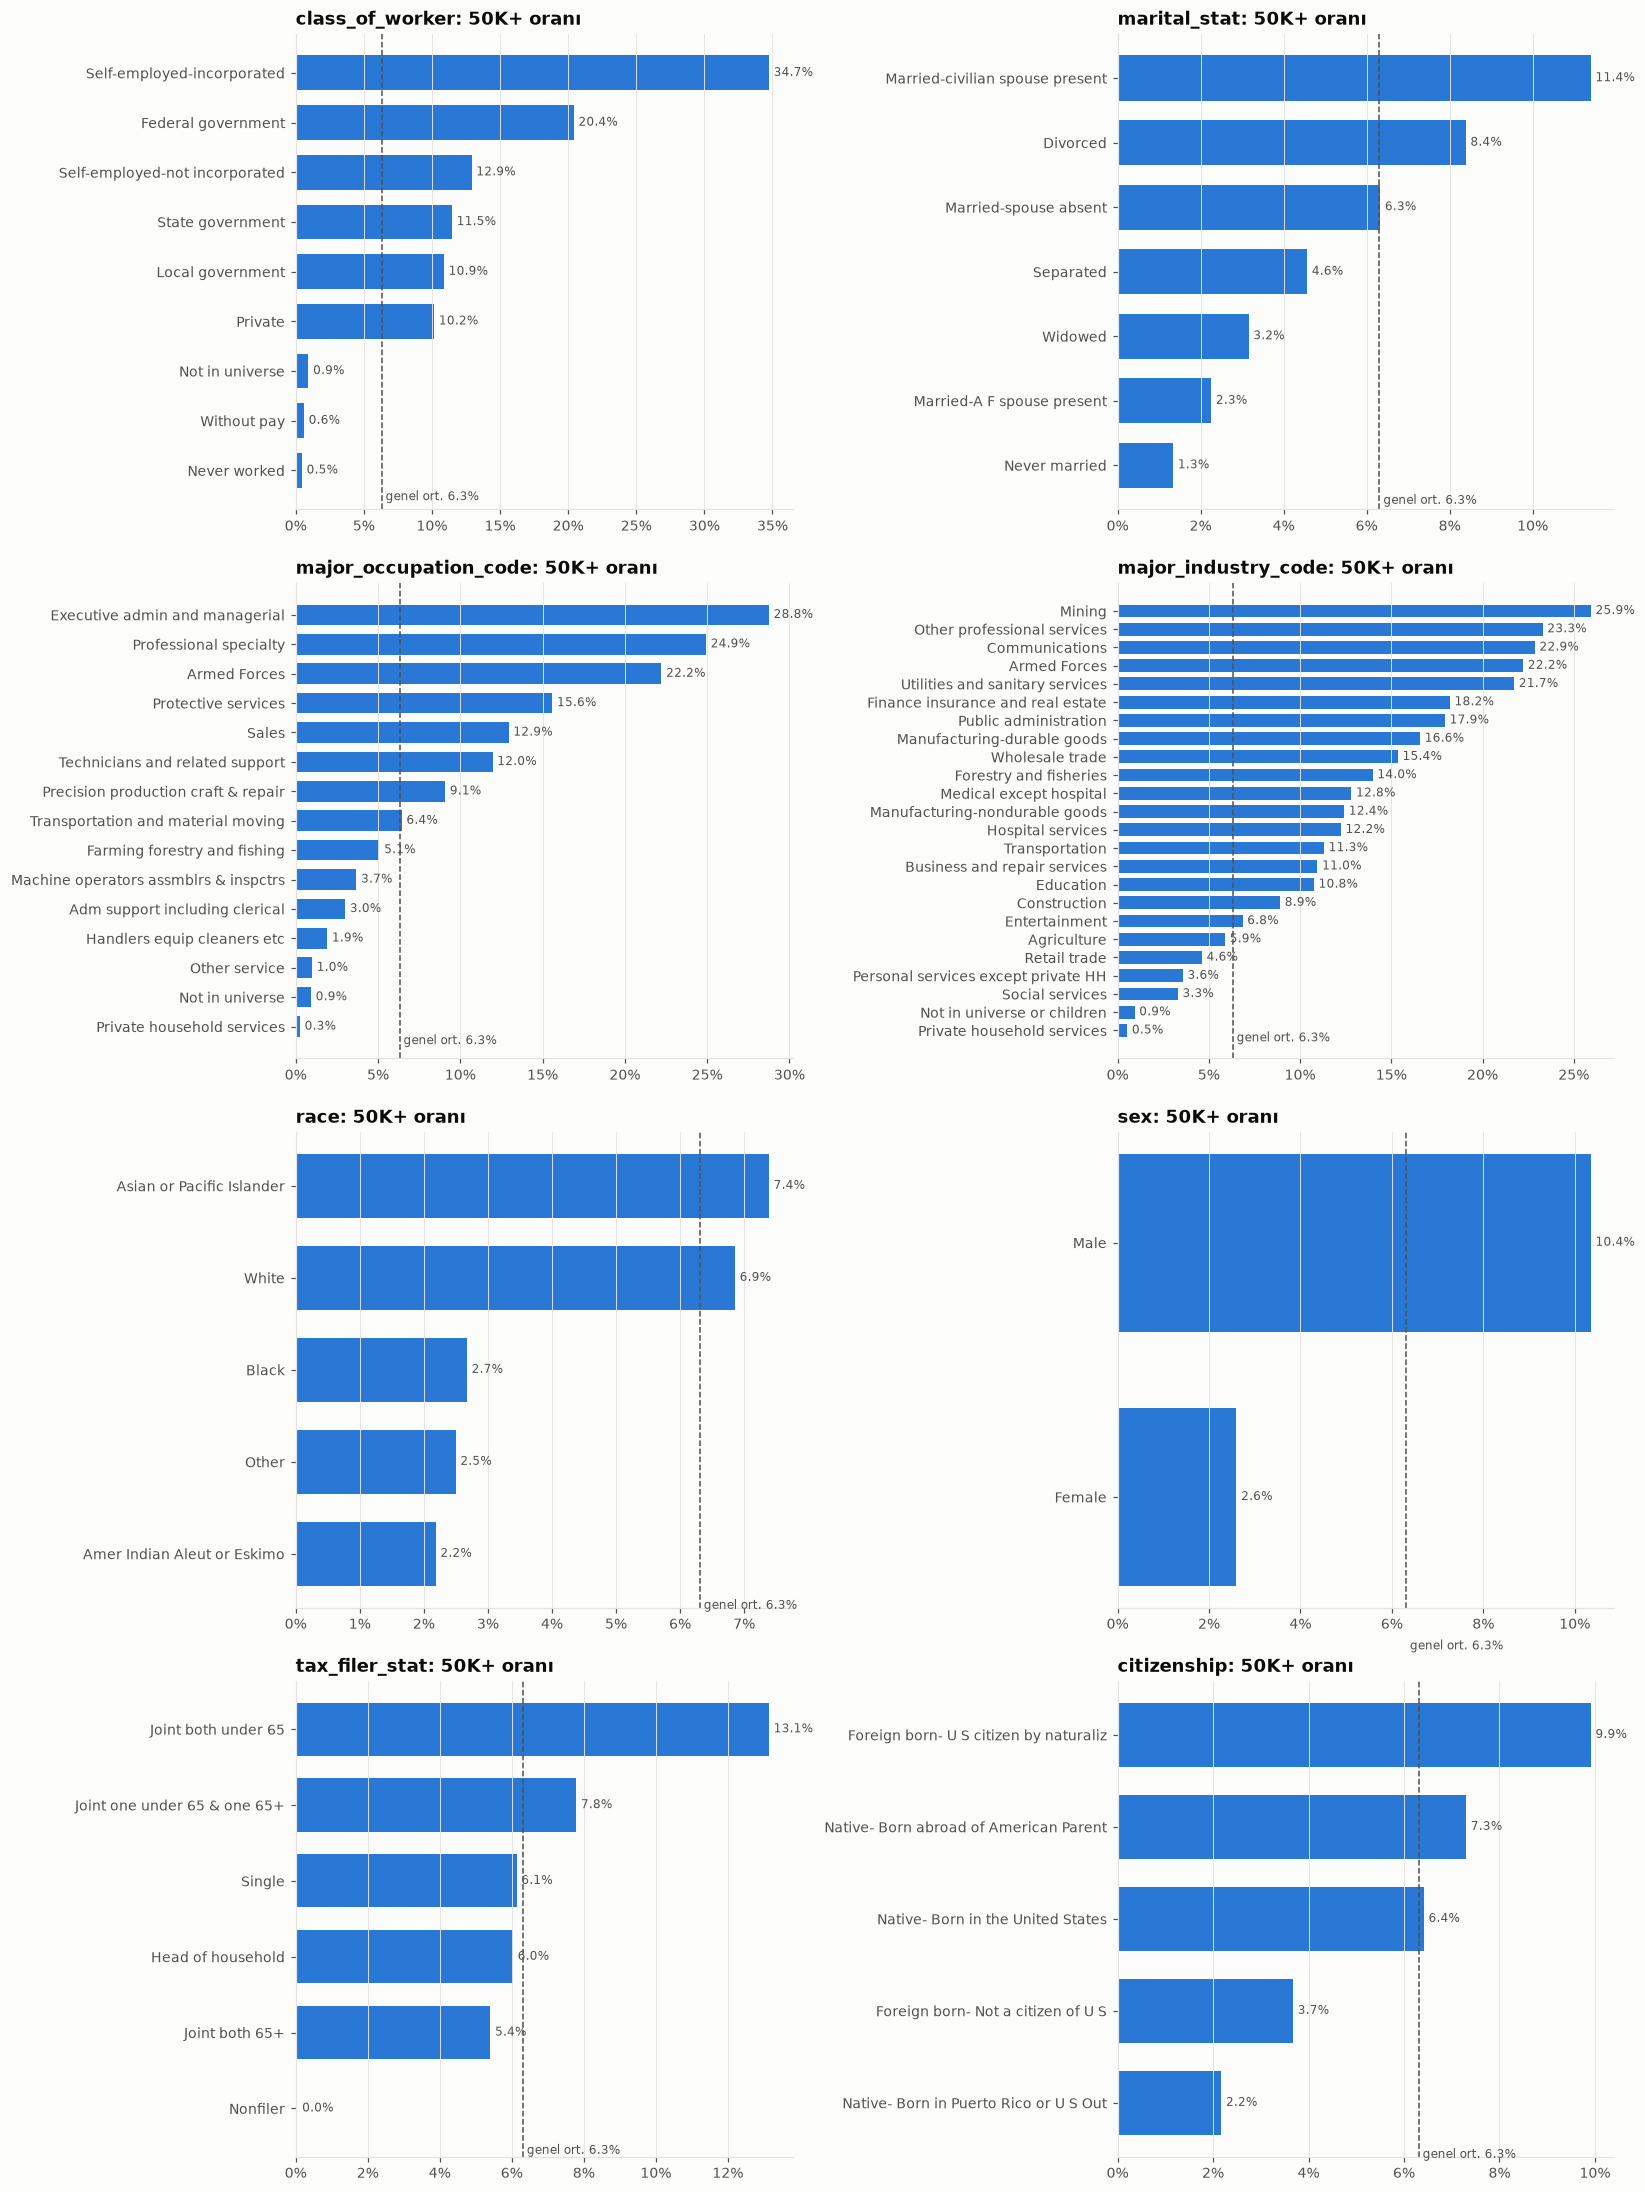

In [17]:
cols = ["class_of_worker", "marital_stat", "major_occupation_code", "major_industry_code",
        "race", "sex", "tax_filer_stat", "citizenship"]
fig, axes = plt.subplots(4, 2, figsize=(15, 20))
for ax, c in zip(axes.ravel(), cols):
    s = (100 * train.groupby(c)[TARGET].mean()).sort_values(ascending=False)
    s.index = [str(i)[:38] for i in s.index]
    rate_bar(ax, s, f"{c}: 50K+ oranı", BASE_RATE)
plt.tight_layout(); plt.show()

**Gözlemler:**
- **Meslek:** *Executive admin and managerial* ve *Professional specialty* en yüksek orana sahip
  (`is_professional_occ` özelliği buradan geliyor).
- **Çalışan sınıfı:** *Self-employed-incorporated* (şirketleşmiş serbest meslek) belirgin şekilde önde.
- **Medeni durum / vergi:** Evli ve *Joint* (ortak) beyanname verenlerde oran çok daha yüksek.
- **Cinsiyet:** Erkeklerde 50K+ oranı kadınlara göre kat kat fazla – bir model bu ayrımı öğrenecektir;
  adillik (fairness) açısından raporlanması gereken bir nokta.

## 7. İki Değişkenli / Etkileşim Analizleri

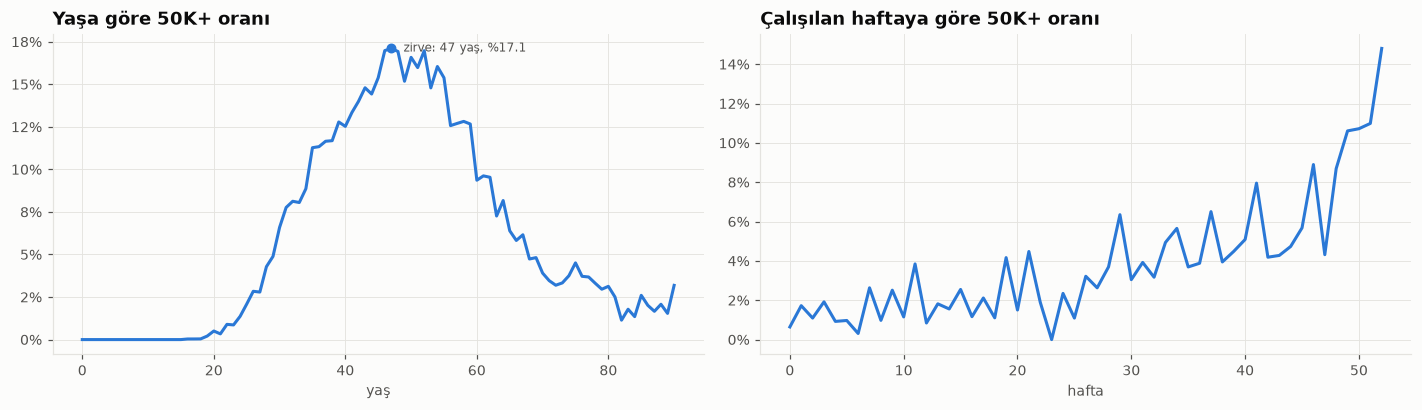

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
a = 100 * train.groupby("age")[TARGET].mean()
axes[0].plot(a.index, a.values, color=C_MAIN, lw=2)
pk = a.idxmax(); axes[0].scatter([pk], [a[pk]], color=C_MAIN, s=30, zorder=3)
axes[0].annotate(f"zirve: {pk} yaş, %{a[pk]:.1f}", (pk, a[pk]), xytext=(8, 0),
                 textcoords="offset points", fontsize=8, color=C_MUTED, va="center")
axes[0].set_title("Yaşa göre 50K+ oranı"); axes[0].set_xlabel("yaş"); pct_axis(axes[0])

w = 100 * train.groupby("weeks_worked_in_year")[TARGET].mean()
axes[1].plot(w.index, w.values, color=C_MAIN, lw=2)
axes[1].set_title("Çalışılan haftaya göre 50K+ oranı"); axes[1].set_xlabel("hafta"); pct_axis(axes[1])
plt.tight_layout(); plt.show()

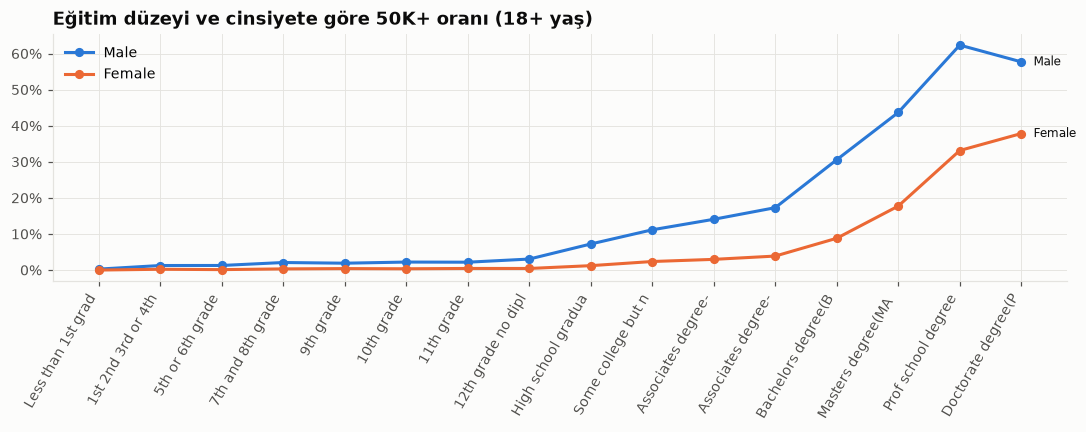

In [19]:
# Eğitim düzeyi x cinsiyet  (yalnızca 18+ yaş)
adults = train[train["age"] >= 18]
p = 100 * adults.pivot_table(index="education_level", columns="sex", values=TARGET, aggfunc="mean")
inv = {v: k for k, v in EDUCATION_LEVELS.items()}
fig, ax = plt.subplots(figsize=(10, 4))
for sex, color in [("Male", C_LOW), ("Female", C_HIGH)]:
    ax.plot(p.index, p[sex], marker="o", ms=5, lw=2, color=color, label=sex)
    ax.text(p.index[-1] + 0.2, p[sex].iloc[-1], sex, color=C_INK, fontsize=8, va="center")
ax.set_xticks(p.index, [inv[i][:18] for i in p.index], rotation=60, ha="right")
ax.set_title("Eğitim düzeyi ve cinsiyete göre 50K+ oranı (18+ yaş)"); pct_axis(ax); ax.legend()
plt.tight_layout(); plt.show()

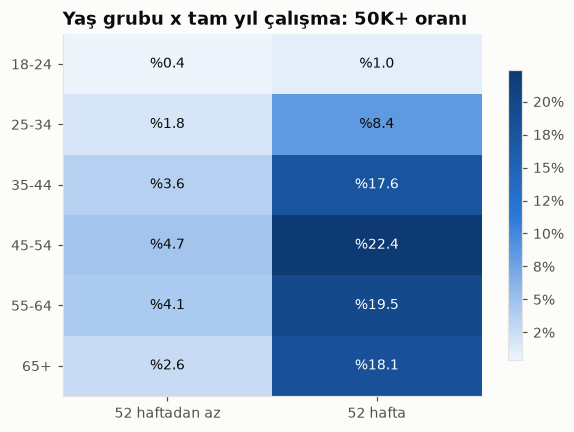

In [20]:
# Yaş grubu x tam yıl çalışma -> ısı haritası
h = 100 * adults.pivot_table(index="age_group", columns="full_year_worker", values=TARGET, aggfunc="mean")
h = h.reindex([a for a in AGE_LABELS if a in h.index]).rename(columns={0: "52 haftadan az", 1: "52 hafta"})
fig, ax = plt.subplots(figsize=(5.5, 4))
im = ax.imshow(h.values, cmap=SEQ, aspect="auto")
ax.set_xticks(range(h.shape[1]), h.columns); ax.set_yticks(range(h.shape[0]), h.index); ax.grid(False)
for i in range(h.shape[0]):
    for j in range(h.shape[1]):
        v = h.values[i, j]
        ax.text(j, i, f"%{v:.1f}", ha="center", va="center", fontsize=9,
                color="white" if v > h.values.max() * 0.55 else C_INK)
ax.set_title("Yaş grubu x tam yıl çalışma: 50K+ oranı")
fig.colorbar(im, ax=ax, format=mticker.PercentFormatter(100, decimals=0), shrink=0.8)
plt.tight_layout(); plt.show()

> Etkileşimler belirgin: aynı yaş grubunda tam yıl çalışanların 50K+ oranı birkaç kat yüksek; aynı
> eğitim düzeyinde erkeklerin oranı kadınlarınkinin üzerinde. Ağaç tabanlı modeller (Random Forest,
> Gradient Boosting) bu tür etkileşimleri kendiliğinden yakalar; lojistik regresyonda etkileşim
> terimleri eklemek gerekebilir.

## 8. Korelasyon ve İlişki Gücü

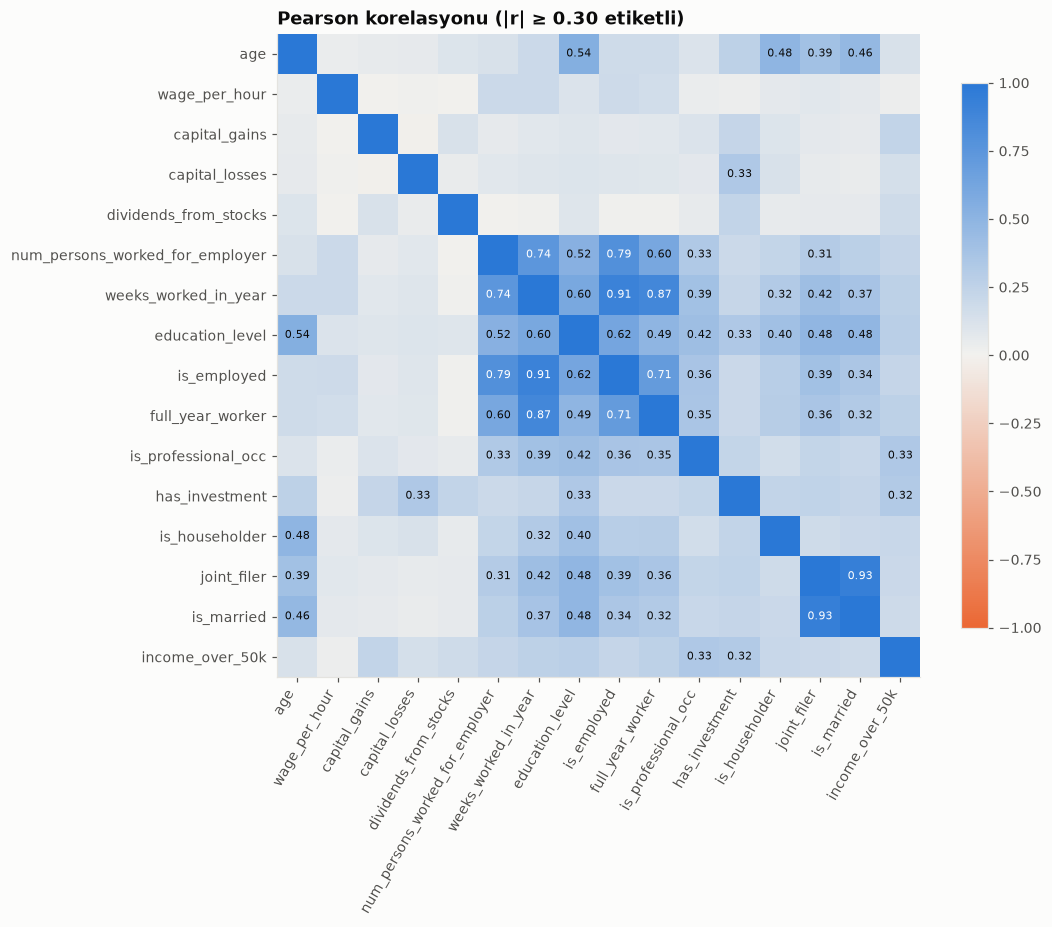

In [21]:
# Sayısal + türetilmiş ikili özellikler arasındaki Pearson korelasyonu (instance_weight hariç)
corr_cols = [c for c in NUMERIC_COLS if c != "instance_weight"] + \
            [c for c in DERIVED_COLS if c != "age_group"] + [TARGET]
corr = train[corr_cols].corr()
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.values, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), corr.columns); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        if i != j and abs(v) >= 0.3:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.7 else C_INK)
ax.set_title("Pearson korelasyonu (|r| ≥ 0.30 etiketli)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

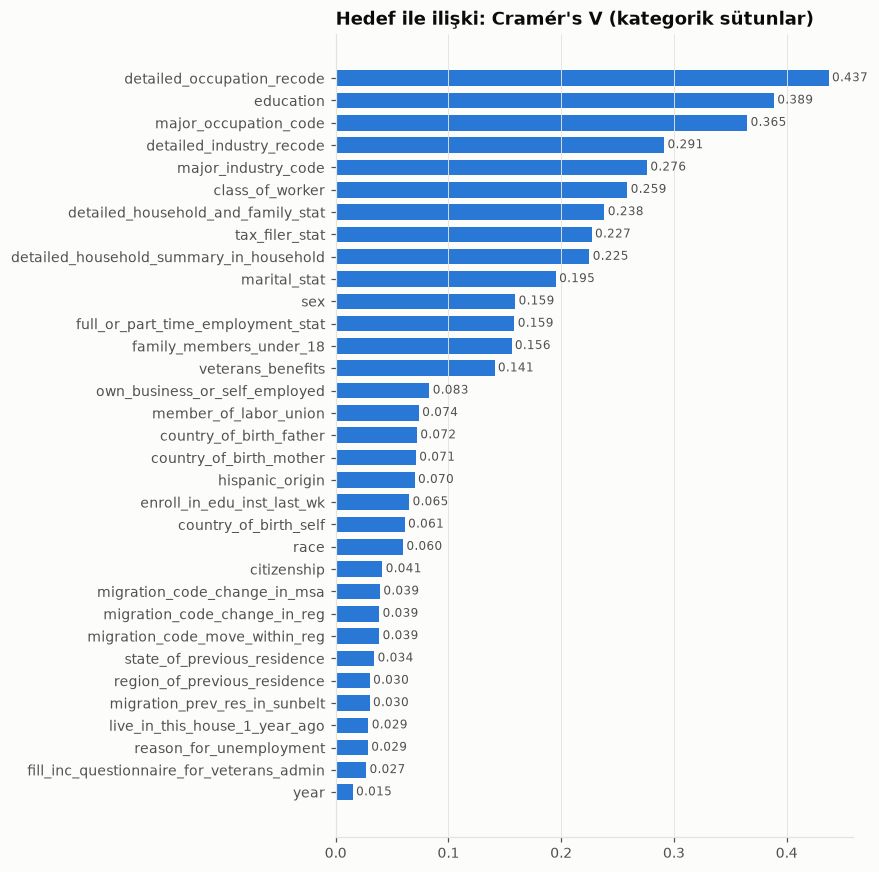

In [22]:
# Kategorik sütunlar için hedefle ilişki: Cramér's V
def cramers_v(x, y):
    ct = pd.crosstab(x.fillna("NA"), y)
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

cv = pd.Series({c: cramers_v(train[c].astype(str), train[TARGET]) for c in CAT_COLS}).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(cv.index, cv.values, color=C_MAIN, height=0.7)
for i, v in enumerate(cv.values):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8, color=C_MUTED)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_title("Hedef ile ilişki: Cramér's V (kategorik sütunlar)")
plt.tight_layout(); plt.show()

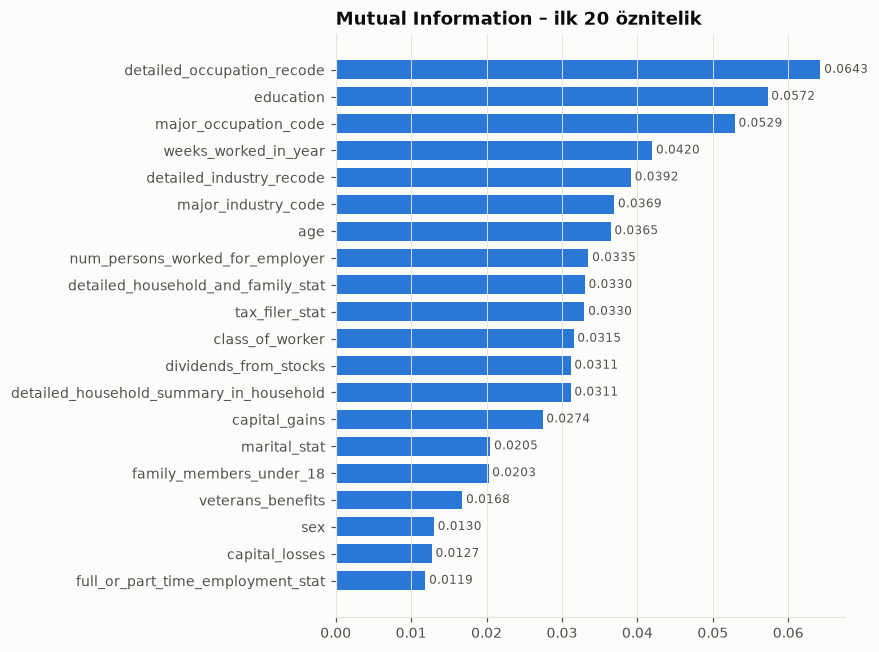

In [23]:
# Tüm öznitelikler için Mutual Information (hedefle paylaşılan bilgi)
# Hız için 60.000 satırlık tabakalı örneklem
sample = pd.concat([g.sample(frac=60_000 / len(train), random_state=42) for _, g in train.groupby(TARGET)])
feat = [c for c in train_raw.columns if c not in ("instance_weight", TARGET)]
X = sample[feat].copy()
discrete = []
for c in feat:
    if c in NUMERIC_COLS:
        discrete.append(False)
    else:
        X[c] = pd.factorize(X[c].astype(str))[0]; discrete.append(True)
mi = pd.Series(mutual_info_classif(X, sample[TARGET], discrete_features=discrete, random_state=42),
               index=feat).sort_values(ascending=False)
top = mi.head(20)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=C_MAIN, height=0.7)
for i, v in enumerate(top.values):
    ax.text(v + 0.0005, i, f"{v:.4f}", va="center", fontsize=8, color=C_MUTED)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_title("Mutual Information – ilk 20 öznitelik")
plt.tight_layout(); plt.show()

> Cramér's V ve Mutual Information aynı tabloyu çiziyor: **meslek/sektör kodları, eğitim, yaş,
> çalışılan hafta, vergi beyan durumu, hane durumu ve sermaye kazancı** en bilgilendirici değişkenler.
> `migration_*`, `region/state_of_previous_residence`, `fill_inc_questionnaire_for_veterans_admin`
> gibi sütunlar hedefle neredeyse hiç bilgi paylaşmıyor – modelden çıkarılmaya adaylar.

## 9. Türetilmiş Özellikler

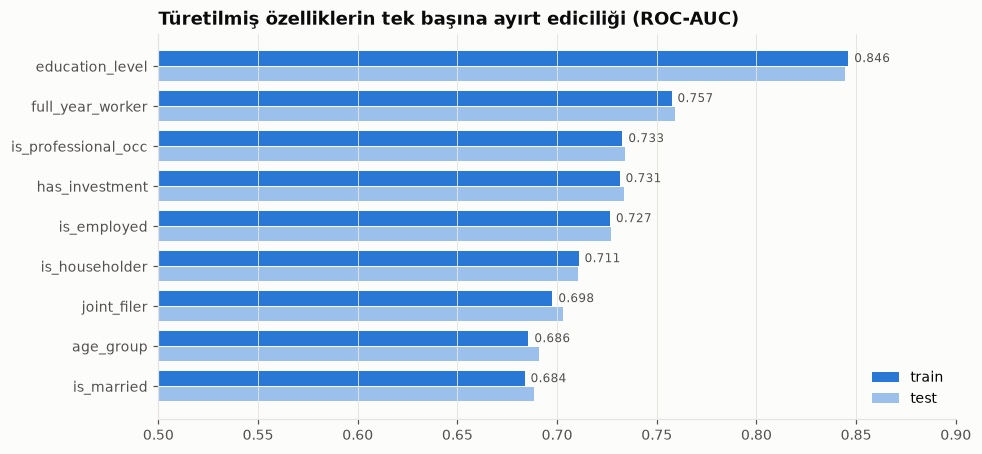

In [24]:
age_code = {l: i for i, l in enumerate(AGE_LABELS)}
auc = {}
for c in DERIVED_COLS:
    row = {}
    for name, df in [("train", train), ("test", test)]:
        x = df[c].map(age_code) if c == "age_group" else df[c]
        a_ = roc_auc_score(df[TARGET], x); row[name] = max(a_, 1 - a_)
    auc[c] = row
auc = pd.DataFrame(auc).T.sort_values("train", ascending=True)

fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(auc)); bh = 0.36
ax.barh(y + bh / 2 + 0.01, auc["train"], bh, color=C_MAIN, label="train")
ax.barh(y - bh / 2 - 0.01, auc["test"], bh, color="#9bc0ec", label="test")
for i, v in enumerate(auc["train"]):
    ax.text(v + 0.003, i + bh / 2, f"{v:.3f}", va="center", fontsize=8, color=C_MUTED)
ax.set_yticks(y, auc.index); ax.set_xlim(0.5, 0.9); ax.grid(axis="y", visible=False)
ax.axvline(0.5, color=C_MUTED, lw=1)
ax.set_title("Türetilmiş özelliklerin tek başına ayırt ediciliği (ROC-AUC)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

In [25]:
# İkili özelliklerde 1 / 0 değerine göre 50K+ oranı ve oran çarpanı (lift)
binary = [c for c in DERIVED_COLS if c not in ("age_group", "education_level")]
lift = pd.DataFrame({
    "=1 kayıt %": [100 * train[c].mean() for c in binary],
    "=0 → 50K+ %": [100 * train.loc[train[c] == 0, TARGET].mean() for c in binary],
    "=1 → 50K+ %": [100 * train.loc[train[c] == 1, TARGET].mean() for c in binary],
}, index=binary)
lift["çarpan"] = lift["=1 → 50K+ %"] / lift["=0 → 50K+ %"]
lift.sort_values("çarpan", ascending=False)

,=1 kayıt %,=0 → 50K+ %,=1 → 50K+ %,çarpan
is_employed,52.739,0.642,11.385,17.721
full_year_worker,35.818,1.568,14.802,9.442
is_professional_occ,13.467,3.128,26.737,8.546
has_investment,14.954,3.092,24.596,7.954
is_householder,38.443,2.260,12.789,5.659
joint_filer,40.530,2.380,12.072,5.073
is_married,44.003,2.430,11.243,4.627


## 10. Train – Test Dağılım Karşılaştırması

In [26]:
# Population Stability Index (PSI): < 0.1 kararlı, 0.1-0.25 orta kayma, > 0.25 ciddi kayma
def psi(a, b, bins=10):
    if a.dtype.kind in "if" and a.nunique() > 20:
        edges = np.unique(np.quantile(a.dropna(), np.linspace(0, 1, bins + 1)))
        edges[0], edges[-1] = -np.inf, np.inf
        pa = pd.cut(a, edges).value_counts(normalize=True)
        pb = pd.cut(b, edges).value_counts(normalize=True)
    else:
        pa = a.astype(str).value_counts(normalize=True)
        pb = b.astype(str).value_counts(normalize=True)
    idx = pa.index.union(pb.index)
    pa = pa.reindex(idx, fill_value=0) + 1e-6; pb = pb.reindex(idx, fill_value=0) + 1e-6
    return float(((pa - pb) * np.log(pa / pb)).sum())

psi_s = pd.Series({c: psi(train[c], test[c]) for c in feat}).sort_values(ascending=False)
print("PSI > 0.1 olan sütun sayısı:", int((psi_s > 0.1).sum()))
psi_s.head(10).to_frame("PSI")

PSI > 0.1 olan sütun sayısı: 0


,PSI
state_of_previous_residence,0.001
country_of_birth_mother,0.001
migration_code_move_within_reg,0.001
migration_code_change_in_msa,0.001
country_of_birth_father,0.001
major_industry_code,0.001
detailed_household_and_family_stat,0.001
migration_code_change_in_reg,0.001
country_of_birth_self,0.001
education,0.000


> Train ve test aynı anketlerden (1994–1995) rastgele bölündüğü için dağılımlar neredeyse aynı;
> PSI değerleri çok düşük. Yani test kümesi üzerindeki model performansı güvenilir bir tahmin olacaktır.

## 11. Aykırı ve Kesilmiş (Top-coded) Değerler

In [27]:
rows = []
for c in [c for c in NUMERIC_COLS if c != "instance_weight"]:
    s = train[c]; nz = s[s > 0] if c in money else s
    q1, q3 = nz.quantile([.25, .75]); iqr = q3 - q1
    rows.append({
        "sütun": c, "max": s.max(), "max değerindeki kayıt": int((s == s.max()).sum()),
        "IQR aykırı (sıfır hariç) %": 100 * ((nz < q1 - 1.5 * iqr) | (nz > q3 + 1.5 * iqr)).mean(),
    })
pd.DataFrame(rows).set_index("sütun")

,max,max değerindeki kayıt,IQR aykırı (sıfır hariç) %
sütun,,,
age,90,722,0.000
wage_per_hour,9999,1,3.565
capital_gains,99999,390,7.318
capital_losses,4608,4,8.577
dividends_from_stocks,99999,25,12.414
num_persons_worked_for_employer,6,36507,0.000
weeks_worked_in_year,52,70308,0.000


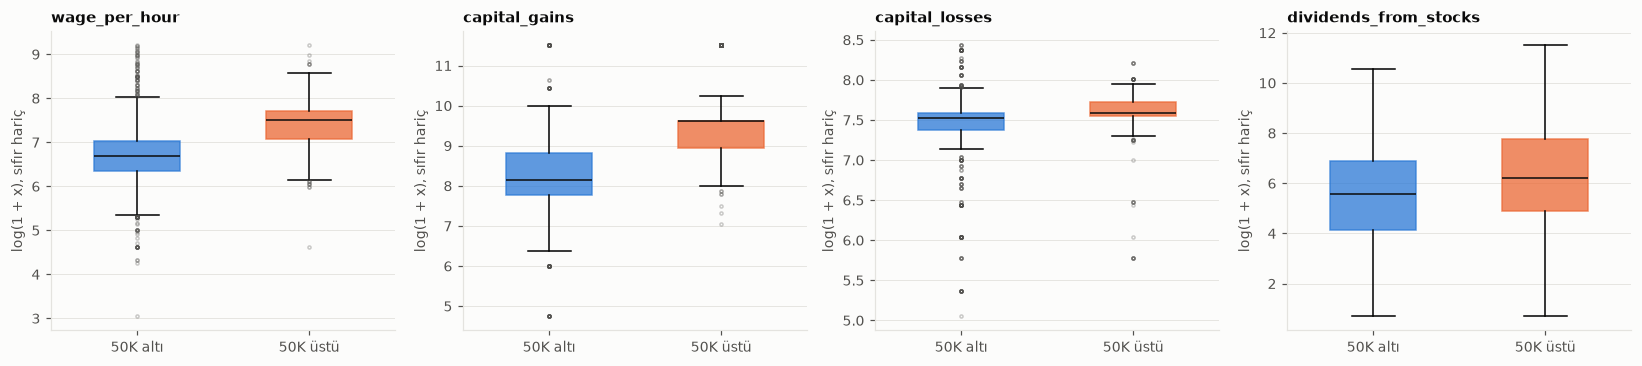

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, c in zip(axes, money):
    data = [np.log1p(train.loc[(train[c] > 0) & (train[TARGET] == t), c]) for t in [0, 1]]
    bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=True,
                    flierprops=dict(marker="o", ms=2, alpha=0.3, mec=C_MUTED),
                    medianprops=dict(color=C_INK))
    for patch, t in zip(bp["boxes"], [0, 1]):
        patch.set_facecolor(CLASS_COLORS[t]); patch.set_alpha(0.75); patch.set_edgecolor(CLASS_COLORS[t])
    ax.set_xticks([1, 2], [CLASS_NAMES[0], CLASS_NAMES[1]]); ax.set_title(c, fontsize=10)
    ax.set_ylabel("log(1 + x), sıfır hariç"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

> `capital_gains` (390 kayıt) ve `dividends_from_stocks` (25 kayıt) **99999** değerinde yığılıyor – bu
> anketin **kesme (top-coding)** değeri; gerçek değer daha büyük olabilir. `wage_per_hour` en fazla 9999
> (büyük ihtimalle cent cinsinden, 99.99 $/saat) ama bu değerde yalnızca 1 kayıt var. Aykırı değer olarak silinmemeli,
> çünkü çoğu gerçekten yüksek gelirli kişiler ve hedefle güçlü ilişkili. Log dönüşümü yeterli.

## 12. Özet Bulgular ve Öneriler

### Veri kalitesi
- Birebir aynı satırlar silindi; "ağırlık hariç aynı" satırlar farklı kişiler olduğu için korundu.
- `?` eksikleri yalnızca birkaç sütunda: `migration_*` (1995'te tamamen yok – yapısal eksiklik),
  `migration_prev_res_in_sunbelt`, `country_of_birth_*` ve `hispanic_origin` (küçük oranlar).
- "Not in universe" eksik değil; ayrı kategori olarak tutulmalı ve kendisi bir düşük gelir sinyali.
- Para birimli sütunlar %90+ sıfır ve aşırı çarpık; üst değerleri kesilmiş (top-coded).

### Gelirle en güçlü ilişkili faktörler
1. **Eğitim düzeyi** – düzey arttıkça oran monoton artıyor (doktora / profesyonel okul en üstte).
2. **Meslek ve sektör** – yönetici ve profesyonel meslekler.
3. **Çalışma yoğunluğu** – yılın 52 haftası çalışmak.
4. **Yaş** – 45–55 civarında zirve; 18 yaş altı neredeyse hiç 50K+ yok.
5. **Yatırım geliri** – sermaye kazancı / temettü > 0.
6. **Hane / medeni / vergi durumu** – evli, hane reisi, ortak beyanname.
7. **Cinsiyet** – erkeklerde oran belirgin şekilde yüksek (fairness açısından raporlanmalı).

### Modelleme için öneriler
- `instance_weight` öznitelik olarak **kullanılmamalı** (istenirse `sample_weight`).
- `migration_*` ve bilgi taşımayan sütunlar çıkarılmalı ya da `Unknown` kategorisiyle tutulmalı.
- Para sütunlarına `log1p` + `> 0` bayrağı; yüksek kardinaliteli kodlara gruplama / target encoding.
- Dengesizlik: `class_weight='balanced'`, metrik olarak ROC-AUC / PR-AUC / F1.
- Etkileşimler güçlü → Gradient Boosting / Random Forest iyi bir başlangıç; lojistik regresyon
  yorumlanabilir taban model (baseline) olarak kullanılabilir.

### Veritabanı tasarımı için
- Kategorik metin sütunları lookup tablolarına; `detailed → major` industry/occupation iki seviyeli
  hiyerarşi; `country_of_birth_father/mother/self` aynı `Country` tablosuna 3 FK.
- `education_level` sırası `Education` tablosunda `level` sütunu olarak tutulmalı.